In [1]:
import pandas as pd
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

data_fake = pd.read_csv('Fake.csv')
data_true = pd.read_csv('True.csv')

data_fake['class'] = 0
data_true['class'] = 1

data_merge = pd.concat([data_fake, data_true], axis=0)
data = data_merge.sample(frac=1).reset_index(drop=True)

data = data[['text', 'class']]

def wordopt(text):
    if ' - ' in text[:100]:
        text = text.split(' - ', 1)[1]
        
    text = text.lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\n', ' ', text)
    text = re.sub(r'\w*\d\w*', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# data_merge.sample(10)
# data.head(10)

In [3]:
print("Text cleaning start ho raha hai...")
data['text'] = data['text'].apply(wordopt)

print("Dropping NaN values...")
print("Pehle Nulls the:\n", data.isnull().sum())

data = data.dropna()
data = data.reset_index(drop=True)

print("Ab Nulls hain:\n", data.isnull().sum())

Text cleaning start ho raha hai...
Dropping NaN values...
Pehle Nulls the:
 text     0
class    0
dtype: int64
Ab Nulls hain:
 text     0
class    0
dtype: int64


--- Class Distribution ---
class
0    23481
1    21417
Name: count, dtype: int64

--- Percentage Distribution ---
class
0    52.298543
1    47.701457
Name: proportion, dtype: float64


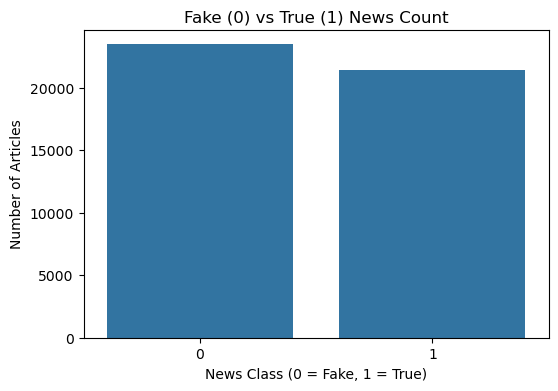

In [4]:
print("--- Class Distribution ---")
class_count = data['class'].value_counts()
print(class_count)

print("\n--- Percentage Distribution ---")
class_percentage = data['class'].value_counts(normalize=True) * 100
print(class_percentage)

plt.figure(figsize=(6,4))
sns.countplot(x='class', data=data)
plt.title('Fake (0) vs True (1) News Count')
plt.xlabel('News Class (0 = Fake, 1 = True)')
plt.ylabel('Number of Articles')
plt.show()

In [5]:
x = data['text']
y = data['class']

x_train, x_test, y_train, y_test, = train_test_split(x, y, test_size=0.2, random_state=42)

print("TF-IDF Vectorization ho rahi hai...")
vectorization = TfidfVectorizer(stop_words='english', max_df=0.7, ngram_range=(1,2), max_features=10000)
xv_train = vectorization.fit_transform(x_train)
xv_test = vectorization.transform(x_test)

print("Logistic Regression train ho raha hai...")
LR = LogisticRegression()
LR.fit(xv_train, y_train)
pred_lr = LR.predict(xv_test)
print("\n--- Logistic Regression Result ---")
print(f"Accuracy: {accuracy_score(y_test, pred_lr)}")
print(classification_report(y_test, pred_lr))

print("Decision Tree train ho raha hai...")
DT = DecisionTreeClassifier()
DT.fit(xv_train, y_train)
pred_dt = DT.predict(xv_test)
print("\n--- Decision Tree Result ---")
print(f"Accuracy: {accuracy_score(y_test, pred_dt)}")
print(classification_report(y_test, pred_dt))

TF-IDF Vectorization ho rahi hai...
Logistic Regression train ho raha hai...

--- Logistic Regression Result ---
Accuracy: 0.9790645879732739
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      4722
           1       0.97      0.98      0.98      4258

    accuracy                           0.98      8980
   macro avg       0.98      0.98      0.98      8980
weighted avg       0.98      0.98      0.98      8980

Decision Tree train ho raha hai...

--- Decision Tree Result ---
Accuracy: 0.9366369710467706
              precision    recall  f1-score   support

           0       0.92      0.96      0.94      4722
           1       0.95      0.91      0.93      4258

    accuracy                           0.94      8980
   macro avg       0.94      0.94      0.94      8980
weighted avg       0.94      0.94      0.94      8980



In [6]:
def manual_testing(news):
    testing_news = {'text': [news]}
    new_def_test = pd.DataFrame(testing_news)
    new_def_test['text'] = new_def_test['text'].apply(wordopt)
    new_x_test = new_def_test["text"]
    new_xv_test = vectorization.transform(new_x_test)
    pred_LR = LR.predict(new_xv_test)
    pred_DT = DT.predict(new_xv_test)

    def output_label(n):
        if n == 0:
            return "Fake News 🚨"
        elif n == 1:
            return "True News ✅"
        
    print(f"\n--- Prediction Results ---")
    print(f"Logistic Regression kehta hai: {output_label(pred_LR[0])}")
    print(f"Decision Tree kehta hai:       {output_label(pred_DT[0])}")
    
        

In [7]:
meri_news = "Narendra modi is a prime minister of an india"
manual_testing(meri_news)


--- Prediction Results ---
Logistic Regression kehta hai: True News ✅
Decision Tree kehta hai:       True News ✅


In [8]:
import pickle

pickle.dump(LR, open('fake_news_model.pkl', 'wb'))
pickle.dump(vectorization, open('fake_news_vectorizer.pkl', 'wb'))